# Kaggle 房价预测

**Step 1｜导入**

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

print(sys.executable)
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("sklearn", sklearn.__version__)

**Step 2 | 数据预处理**

- 导入数据

In [ ]:
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "house_prices"

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("train:", train.shape)
print("test :", test.shape)

- 清理无用数据头（Id）和不合常理的数据
- 房价取对数，防止预测出的房价右偏分布
- 对数据进行独热编码,缺失值处理取中位数

In [ ]:
test_id = test["Id"]
train = train.drop("Id", axis=1)
test = test.drop("Id", axis=1)

train = train.drop(train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)].index)

y = np.log1p(train["SalePrice"])
X = train.drop("SalePrice", axis=1)

print(train.shape, test.shape, y.shape, X.shape)

In [ ]:
num_cols = X.select_dtypes(include=[np.number]).columns
obj_cols = X.select_dtypes(include=["object"]).columns

X[num_cols] = X[num_cols].fillna(X[num_cols].median())
X[obj_cols] = X[obj_cols].fillna("None")
test[num_cols] = test[num_cols].fillna(X[num_cols].median())
test[obj_cols] = test[obj_cols].fillna("None")

combined = pd.concat([X, test], axis=0)
combined = pd.get_dummies(combined,drop_first=True)

X = combined.iloc[:len(X), :].copy()
test = combined.iloc[len(X):, :].copy()

print("数值列", len(num_cols), "类别列", len(obj_cols))
print("独热后", X.shape, test.shape)

- 偏态特征取对数（skew > 1 且取值非负、非年份的数值列）
- 数值特征标准化


In [ ]:
skewed = X[num_cols].skew()
skewed_cols = []

for c in skewed.index:
    if skewed[c] > 1 and X[c].min() >= 0 and not c.startswith("Yr"):
        skewed_cols.append(c)
        X[c] = np.log1p(X[c])
        test[c] = np.log1p(test[c])

print("偏态处理列数", len(skewed_cols))
print(skewed_cols[:8])


In [ ]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
test_scaled = scaler_X.transform(test)
y_scaled = scaler_y.fit_transform(y.values.reshape(-1, 1)).ravel()

print("均值", X_scaled.mean().round(6), "标准差", X_scaled.std().round(6))

- 数据转张量

In [ ]:
X_t = torch.tensor(X_scaled, dtype=torch.float32)
y_t = torch.tensor(y_scaled, dtype=torch.float32).view(-1, 1)
print(X_t.shape, y_t.shape)

**Step 3 | 模型构建与训练**

- 搭ridge、MLP模型

In [ ]:
class Ridge(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x)


class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x)

- 切分

In [ ]:
n = int(len(X_t) * 0.8)

X_tr, y_tr = X_t[:n], y_t[:n]
X_va, y_va = X_t[n:], y_t[n:]

print(X_tr.shape, X_va.shape)


- 损失函数:采用MSE
- 优化器
- 训练函数、预测函数

In [ ]:
loss_fn = nn.MSELoss()

ridge = Ridge(X_t.shape[1])
ridge_optimizer = torch.optim.Adam(ridge.parameters(), lr=0.01,weight_decay = 1.0)

mlp = MLP(X_t.shape[1])
mlp_optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001,weight_decay = 0.1)

def train_one_epoch(model, optimizer, X, y):
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(X), y)
    loss.backward()
    optimizer.step()
    return loss.item()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        return loss_fn(model(X), y).item()

- 对模型进行训练和验证

In [ ]:
epochs = 500

ridge_train_hist, ridge_val_hist = [], []
mlp_train_hist, mlp_val_hist = [], []

for epoch in range(epochs):
    ridge_train_hist.append(train_one_epoch(ridge, ridge_optimizer, X_tr, y_tr))
    ridge_val_hist.append(evaluate(ridge, X_va, y_va))

for epoch in range(epochs):
    mlp_train_hist.append(train_one_epoch(mlp, mlp_optimizer, X_tr, y_tr))
    mlp_val_hist.append(evaluate(mlp, X_va, y_va))

print(f"ridge 训练RMSE：{ridge_train_hist[-1]**0.5:.4f}  验证RMSE：{ridge_val_hist[-1]**0.5:.4f}")
print(f"mlp 训练RMSE：{mlp_train_hist[-1]**0.5:.4f}  验证RMSE：{mlp_val_hist[-1]**0.5:.4f}")

- 画图（用于确认epochs）

In [ ]:
start = 10

plt.figure(figsize=(10, 5))

plt.plot(range(start, len(ridge_train_hist)), ridge_train_hist[start:], label="ridge train")
plt.plot(range(start, len(ridge_val_hist)),   ridge_val_hist[start:],   label="ridge val")
plt.plot(range(start, len(mlp_train_hist)),   mlp_train_hist[start:],   label="mlp train")
plt.plot(range(start, len(mlp_val_hist)),     mlp_val_hist[start:],     label="mlp val")

plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("LOSS")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- cv_rmse: 交叉验证 RMSE
- 每个eopch重新建优化器和模型，以防数据泄露


In [ ]:
def cv_rmse(model_class, wd, epochs, lr, k):
    torch.manual_seed(42)
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    scores = []

    for tr_idx, va_idx in kf.split(X_scaled):
        model = model_class(X_t.shape[1])
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

        X_tr, y_tr = X_t[tr_idx], y_t[tr_idx]
        X_va, y_va = X_t[va_idx], y_t[va_idx]

        for epoch in range(epochs):
            train_one_epoch(model, optimizer, X_tr, y_tr)

        scores.append(evaluate(model, X_va, y_va) ** 0.5)

    return np.mean(scores)

- 通过统一变量法确认各参数的最佳值

In [ ]:
print("以kFold为变量：")
for k in[5, 10, 15, 20, 25]:
    print(f"k = {k}时，RMSE = {cv_rmse(Ridge, wd=0.3, epochs=200, lr=0.01, k=k):.4f}")

In [ ]:
print("以weight decay为变量：")
print("ridge:")
for wd in [0.1, 0.3, 0.5, 0.7, 1.0]:
    print(f"  wd={wd:<6} {cv_rmse(Ridge, wd=wd, epochs=200, lr=0.01, k=20):.4f}")
print("mlp:")
for wd in [0.03, 0.05, 0.08]:
    print(f"  wd={wd:<6} {cv_rmse(MLP, wd=wd, epochs=300, lr=0.003, k=10):.4f}")

In [ ]:
print("以lr为变量：")
for lr in [0.001, 0.003, 0.005]:
    print(f"lr={lr:<6} {cv_rmse(MLP, wd=0.05, epochs=300, lr=lr, k=10):.4f}")

In [ ]:
print(f"ridge CV RMSE: {cv_rmse(Ridge, wd=0.3, epochs=200, lr=0.01, k=20):.4f}")
print(f"mlp CV RMSE: {cv_rmse(MLP, wd=0.05, epochs=300, lr=0.005, k=20):.4f}")

**Step 4 | 预测与提交**

In [ ]:
test_t = torch.tensor(test_scaled, dtype=torch.float32)

def fit_full(model, wd, epochs=200, lr=0.01):
    torch.manual_seed(42)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    for epoch in range(epochs):
        train_one_epoch(model, optimizer, X_t, y_t)
    return model

ridge_full = fit_full(Ridge(X_t.shape[1]), wd=0.3)
mlp_full = fit_full(MLP(X_t.shape[1]), wd=0.05, epochs=300, lr=0.005)

with torch.no_grad():
    ridge_test = ridge_full(test_t).numpy()
    mlp_test = mlp_full(test_t).numpy()

ridge_price = np.expm1(scaler_y.inverse_transform(ridge_test).ravel())
mlp_price = np.expm1(scaler_y.inverse_transform(mlp_test).ravel())

pd.DataFrame({"Id": test_id, "SalePrice": ridge_price}).to_csv("submission_ridge.csv", index=False)
pd.DataFrame({"Id": test_id, "SalePrice": mlp_price}).to_csv("submission_mlp.csv", index=False)

print("ridge 均值", ridge_price.mean().round(0), "最小", ridge_price.min().round(0), "最大", ridge_price.max().round(0))
print("mlp   均值", mlp_price.mean().round(0), "最小", mlp_price.min().round(0), "最大", mlp_price.max().round(0))


- 补充：正反向影响前五的条件（放在最后以便对着写分析）

In [ ]:
coef = pd.Series(ridge_full.linear.weight.detach().numpy().ravel(), index=X.columns)

print("正向权重前5：")
print(coef.sort_values(ascending=False).head(5))
print("\n反向权重前5：")
print(coef.sort_values().head(5))

**Step 5 | 分析报告**


- **哪些特征对房价影响较大**：正向影响最大的是整体质量（0.129）、居住面积（0.125）、一层面积与地下室面积；负面影响集中在特定社区（MeadowV、IDOTRR）以及厨房、供暖、地下室的“一般”档。
- **模型是否存在过拟合**：判断过拟合，可以从2个方面看：loss曲线、L2正则化的影响。
1. 两个模型的曲线都在走平，训练轮次大只是会加噪点，对过拟合影响比较小，不过主要还是通过统一变量法测试出了适合的学习率，epochs的影响随之减小
2. 通过统一变量法选出了合适的wd，对于mlp来说，耗时太长没法完全确认最佳变量，可能存在轻微过拟合，层数也没有花时间再调整，取了保守的两层。
- **后续如何进一步优化**：
1. 加入早停机制：进步不大就停，自动锁定最优epochs，不用再费心思看图有没有收敛；
2. 特折工程：对偏态数值特征取对数，能有效降低误差。

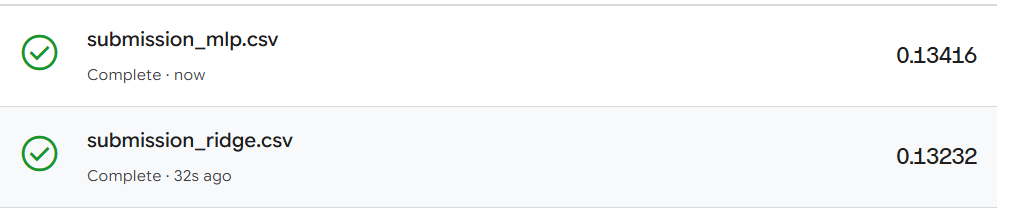
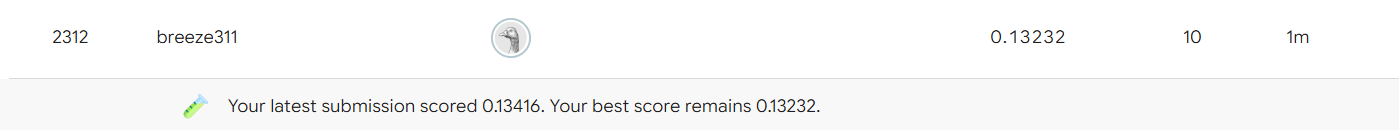